In [17]:
import pandas as pd
df=pd.read_csv("googleplaystore_cleaned.csv")

<Figure size 800x800 with 0 Axes>

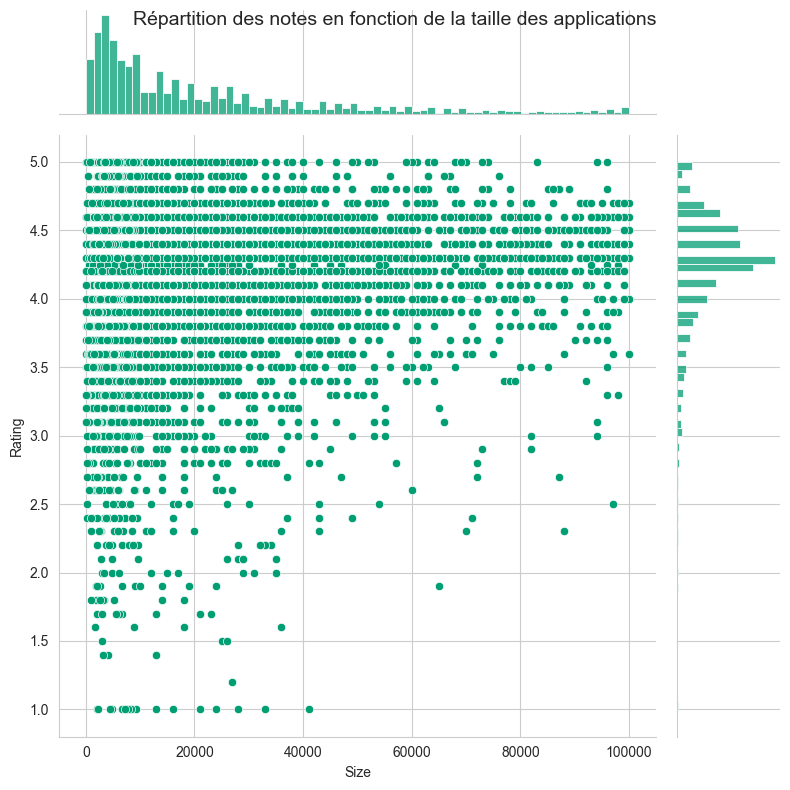

In [18]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set_style("whitegrid")  # Style Seaborn
plt.figure(figsize=(8, 8))  # Taille de la figure (optionnel)

g=sns.jointplot(
    x="Size",
    y="Rating",
    data=df,
    kind="scatter",        # "scatter" pour le nuage de points
    height=8,             # Taille globale de la figure
    marginal_kws={"bins": 70},
    color="#009E73" # Nombre de bins pour l'histogramme
)
g.fig.suptitle("Répartition des notes en fonction de la taille des applications", fontsize=14)

plt.show()


In [19]:
import pandas as pd
import plotly.express as px





# Filtrer uniquement les catégories "GAME" et "FAMILY" et les applications > 50MB
filtered_df = df[(df["Category"].isin(["GAME", "FAMILY"])) & (df["Size"] > 50)]

# Créer le scatter plot avec Plotly
fig = px.scatter(
    filtered_df,
    x="Rating",  
    y="Size",
    color="Category",  # Differentiation par couleur
    title="Rating vs Size",
    labels={"Rating": "Rating", "Size": "Size (in MB)"},
)

# Afficher le graphique
fig.show()


In [20]:
import plotly.express as px

fig1 = px.histogram(
    df,
    x='Size',
    nbins=30,
    title='Distribution de la taille des applications (MB)',
    labels={'Size': 'Taille (MB)'},
    color_discrete_sequence=['#0072B2'],
    template="simple_white" 
)
fig1.show()


In [21]:
import plotly.express as px
import numpy as np

threshold_mb = 50.0
df['Size_Category'] = np.where(df['Size'] <= threshold_mb, 'Petite', 'Grosse')

# Calcul du nombre moyen d'installations
avg_installs_per_cat = df.groupby('Size_Category')['Installs'].mean().reset_index()

# Création du bar plot avec couleurs personnalisées
fig3 = px.bar(
    avg_installs_per_cat,
    x='Size_Category',
    y='Installs',
    color='Size_Category', 
    title='Nombre moyen d’installations - Petites vs Grosses applications',
    labels={
        'Size_Category': 'Catégorie de taille',
        'Installs': 'Installations moyennes'
    },
    color_discrete_map={
        'Grosse':  "#E69F00",  
        'Petite': '#CC79A7'   
    },
    template="simple_white"
)

fig3.show()


In [22]:
import numpy as np
import plotly.express as px

# Ajout de l’échelle log pour mieux visualiser
df['log_installs'] = np.log1p(df['Installs'])  # log(1 + installs)

fig = px.scatter(
    df,
    x='Size',
    y='log_installs',
    hover_name='App',
    title='Relation entre la taille et le nombre d’installations (échelle logarithmique)',
    labels={
        'Size': 'Taille (MB)',
        'log_installs': 'log(Installations)'
    }
)
fig.show()
